In [22]:
from google.colab import files

uploaded = files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [23]:
#Task 1 — Data Import & Setup
# Import CSV using Pandas

import pandas as pd

df = pd.read_csv("social_media_engagement_5000.csv")

print(df.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [24]:
#○ Check/convert data types
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)
df.info()

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [26]:
# Convert date columns to datetime
df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce")

print(df.dtypes)

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


/tmp/ipykernel_1248/54102126.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce")


In [32]:
df["likes"] = pd.to_numeric(df["likes"], errors="coerce")
df["comments"] = pd.to_numeric(df["comments"], errors="coerce")
df["shares"] = pd.to_numeric(df["shares"], errors="coerce")
df["watch_time_sec"] = pd.to_numeric(df["watch_time_sec"], errors="coerce")
df["engagement_rate"] = pd.to_numeric(df["engagement_rate"], errors="coerce")
df["follower_count"] = pd.to_numeric(df["follower_count"], errors="coerce")

print(df.dtypes)

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
hashtag_count                int64
dtype: object


In [31]:
#Task 2 — Data Cleaning
#● Cleaning Missing Data
# Detect missing values (isnull(), isna())

print(df.isnull().sum())
print(df.isna().sum())

# Handle using: dropna(), fillna(), median/mode, forward/backward-fill
# Duplicate Handling- Identify & remove duplicates

df = df.drop_duplicates()


df["age"] = df["age"].fillna(df["age"].median())
df["likes"] = df["likes"].fillna(df["likes"].median())
df["comments"] = df["comments"].fillna(df["comments"].median())
df["shares"] = df["shares"].fillna(df["shares"].median())

df["gender"] = df["gender"].fillna(df["gender"].mode()[0])
df["sentiment"] = df["sentiment"].fillna(df["sentiment"].mode()[0])

# Remove duplicate rows
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

# Data Formatting
df["posted_at"] = pd.to_datetime(df["posted_at"], dayfirst=True)
df["likes"] = pd.to_numeric(df["likes"], errors="coerce")
df["comments"] = pd.to_numeric(df["comments"], errors="coerce")
df["shares"] = pd.to_numeric(df["shares"], errors="coerce")

print(df.dtypes)

# Fix incorrect data types
# Standardize categories (e.g., gender labels)
df["gender"] = df["gender"].str.strip().str.title()
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["post_type"] = df["post_type"].str.strip().str.lower()
df["post_category"] = df["post_category"].str.strip().str.lower()

# Correct unrealistic values in likes, comments, shares
df.loc[df["likes"] < 0, "likes"] = df["likes"].median()
df.loc[df["comments"] < 0, "comments"] = df["comments"].median()
df.loc[df["shares"] < 0, "shares"] = df["shares"].median()

# Feature Cleaning
# Extract hashtag count
df["hashtag_count"] = df["hashtags"].str.findall(r"#\w+").str.len()

print(df[["hashtags", "hashtag_count"]].head())

# Clean sentiment labels
df["sentiment"] = df["sentiment"].replace({
    "positive ": "positive",
    "negative ": "negative",
    "neutral ": "neutral"
})

print(df["sentiment"].value_counts())

print(df.isnull().sum())
print(df.duplicated().sum())
print(df.head())


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
Duplicates: 0
user_id                      int64
age          

In [33]:
#Task 3 — Data Exploration using Pandas
#Perform the following:


# 1. View dataset structure
print("First 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

# 2. Check data types and information
print("\nData types:")
print(df.dtypes)

print("\nDataset info:")
df.info()

# 3. Summary statistics
print("\nSummary statistics:")
print(df.describe())

print("\nSummary of all columns:")
print(df.describe(include="all"))

# 4. Categorical distributions
print("\nGender distribution:")
print(df["gender"].value_counts())

print("\nUnique post types:")
print(df["post_type"].unique())

print("\nNumber of unique countries:")
print(df["country"].nunique())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nPost category distribution:")
print(df["post_category"].value_counts())

print("\nDevice type distribution:")
print(df["device_type"].value_counts())

# 5. Correlation matrix for numeric columns
print("\nCorrelation matrix:")
print(df.corr(numeric_only=True))

# 6. Groupby summaries

print("\nAverage likes by post type:")
print(df.groupby("post_type")["likes"].mean())

print("\nAverage impressions by country:")
print(df.groupby("country")["impression_count"].mean())

print("\nAverage engagement rate by sentiment:")
print(df.groupby("sentiment")["engagement_rate"].mean())

print("\nAverage likes, comments, and shares by post category:")
print(df.groupby("post_category")[["likes", "comments", "shares"]].mean())

First 5 rows:
   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        Fals

In [35]:

# Task 4: Data Wrangling using Pandas

import numpy as np
import pandas as pd

# 1. Create a new engagement_score column
df["engagement_score"] = df["likes"] + df["comments"] + df["shares"]

# 2. Create hashtag_count column
df["hashtag_count"] = df["hashtags"].fillna("").str.findall(r"#\w+").str.len()

# 3. Groupby summary by post_type
print("Average Engagement Score by Post Type:")
print(df.groupby("post_type")["engagement_score"].mean())

# 4. Groupby summary by country
print("\nAverage Engagement Score by Country:")
print(df.groupby("country")["engagement_score"].mean())

# 5. Groupby summary by sentiment
print("\nAverage Engagement Score by Sentiment:")
print(df.groupby("sentiment")["engagement_score"].mean())



Average Engagement Score by Post Type:
post_type
image    12649.390537
reel     12524.031567
text     12613.243775
video    12664.594286
Name: engagement_score, dtype: float64

Average Engagement Score by Country:
country
Australia    12809.621704
Brazil       12385.983135
Canada       12605.894737
France       12903.384073
Germany      12635.664286
India        12492.701869
Japan        12578.648305
UAE          12757.777336
UK           12384.374239
USA          12575.461078
Name: engagement_score, dtype: float64

Average Engagement Score by Sentiment:
sentiment
negative    12731.498958
neutral     12448.163720
positive    12665.799443
Name: engagement_score, dtype: float64


In [36]:

# Task 5: Statistical Analysis

# Select the required numeric columns
columns = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count"
]

# 1. Mean
print("Mean:")
print(df[columns].mean())

# 2. Median
print("\nMedian:")
print(df[columns].median())

# 3. Mode
print("\nMode:")
print(df[columns].mode().iloc[0])

# 4. Standard Deviation
print("\nStandard Deviation:")
print(df[columns].std())

# 5. Variance
print("\nVariance:")
print(df[columns].var())

# 6. Percentiles
print("\nPercentiles (25%, 50%, 75%):")
print(df[columns].quantile([0.25, 0.50, 0.75]))



Mean:
likes               10106.997400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64

Median:
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

Mode:
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

Standard Deviation:
likes                5702.293017
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

Variance:
likes              3.251615e+07
comments           7.334095e+05
shares             3.

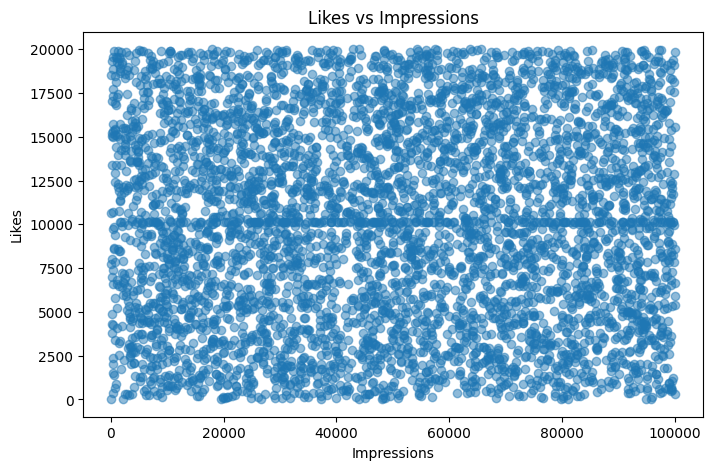

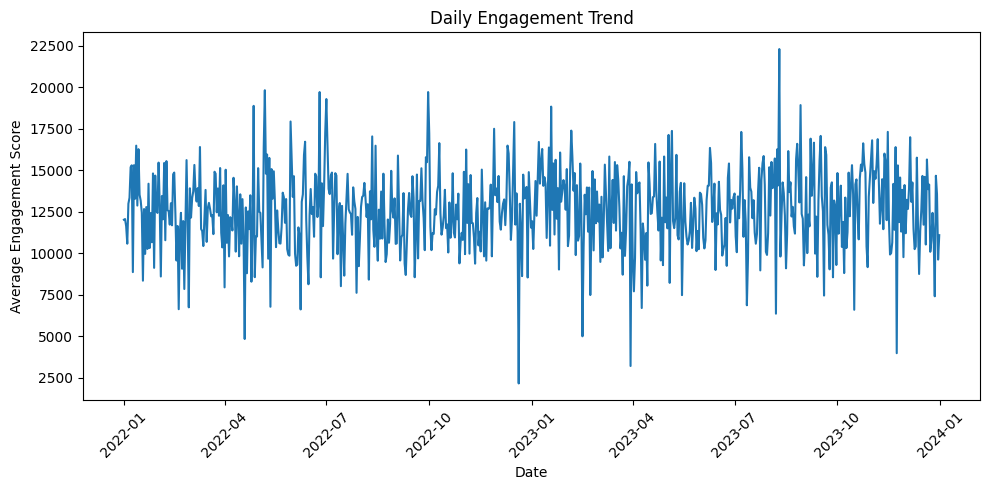

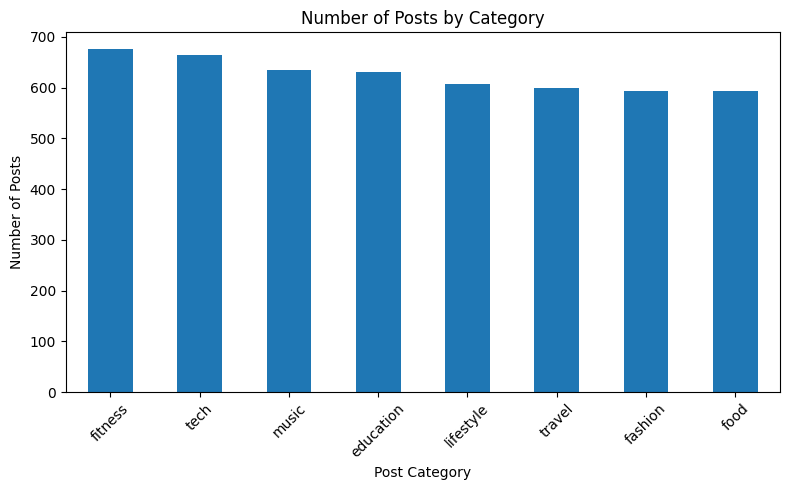

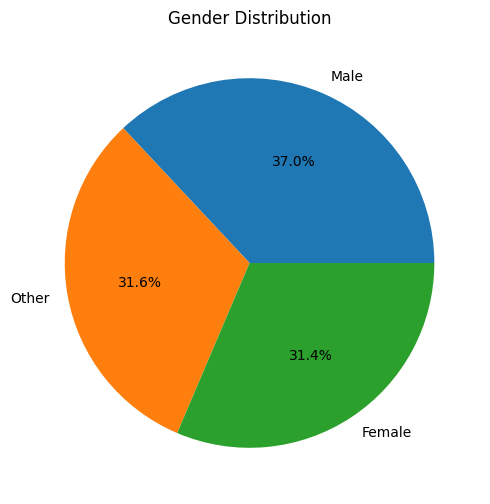

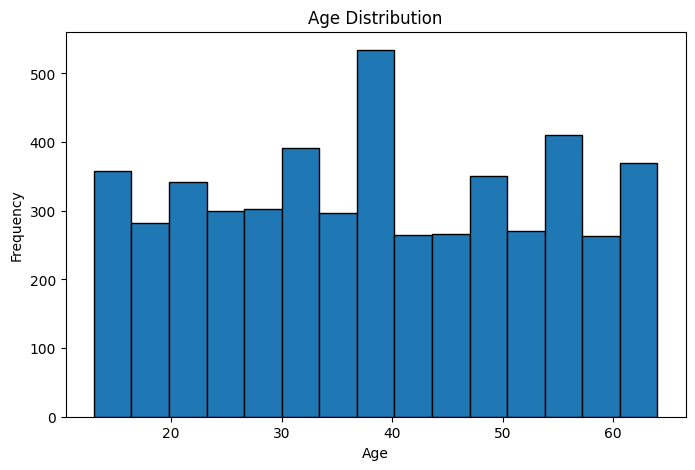

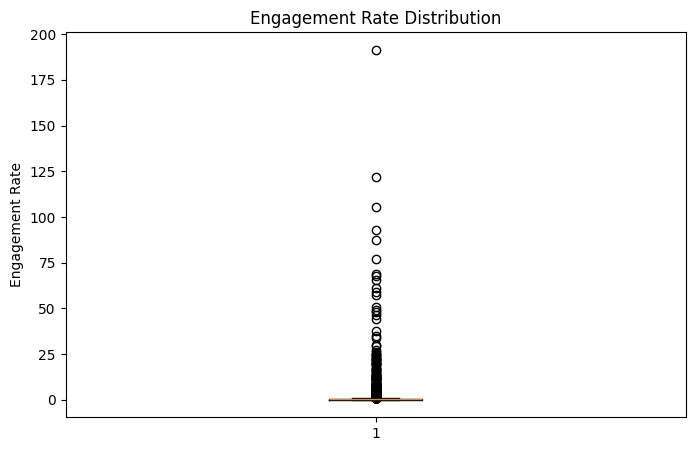

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Scatter plot: Likes vs Impressions
plt.figure(figsize=(8, 5))
plt.scatter(df["impression_count"], df["likes"], alpha=0.5)
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.show()

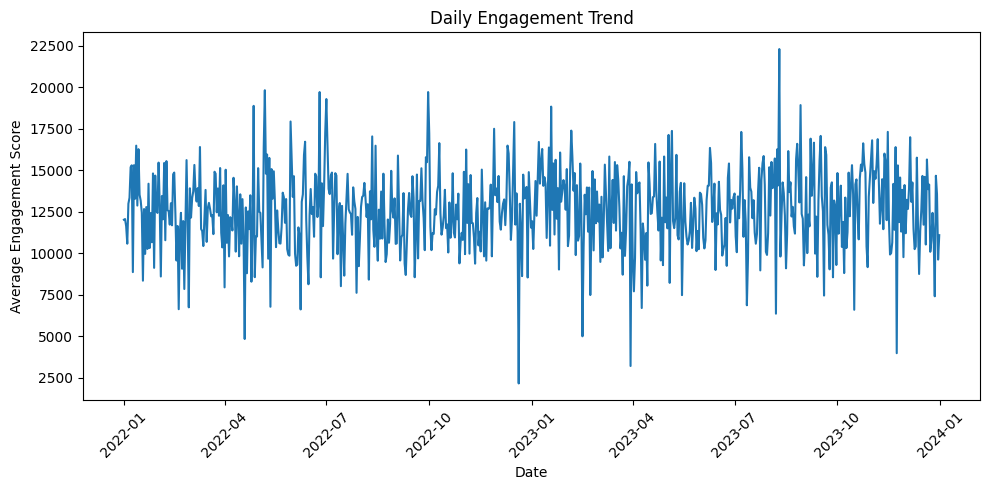

In [39]:
# 2. Line plot: Daily engagement trend
daily_engagement = df.groupby(df["posted_at"].dt.date)["engagement_score"].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.title("Daily Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

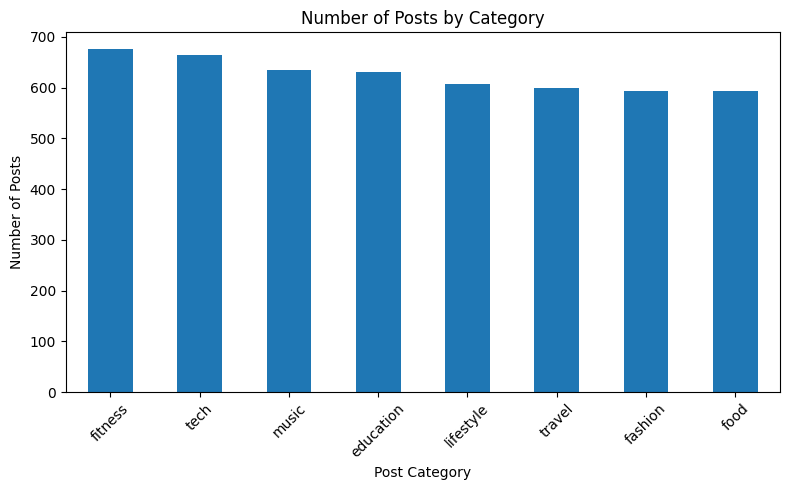

In [40]:
# 3. Bar chart: Posts by category
plt.figure(figsize=(8, 5))
df["post_category"].value_counts().plot(kind="bar")
plt.title("Number of Posts by Category")
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

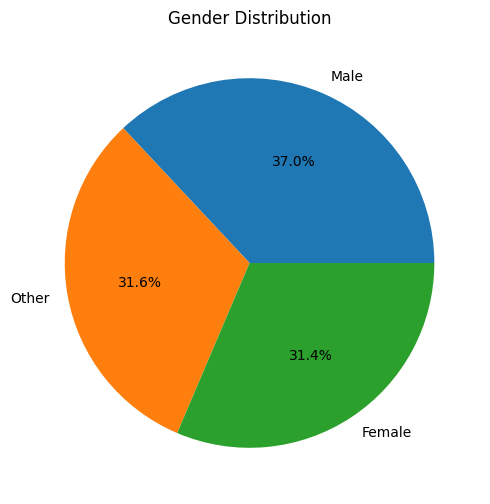

In [41]:
# 4. Pie chart: Gender distribution
df["gender"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", figsize=(6, 6)
)
plt.title("Gender Distribution")
plt.ylabel("")
plt.show()

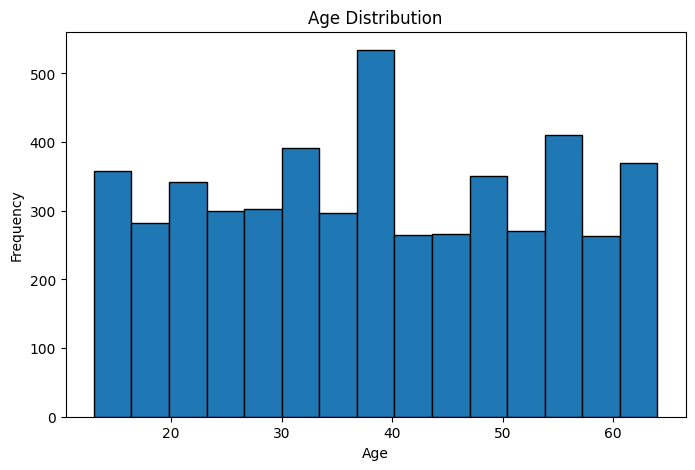

In [42]:
# 5. Histogram: Age distribution
plt.figure(figsize=(8, 5))
plt.hist(df["age"].dropna(), bins=15, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

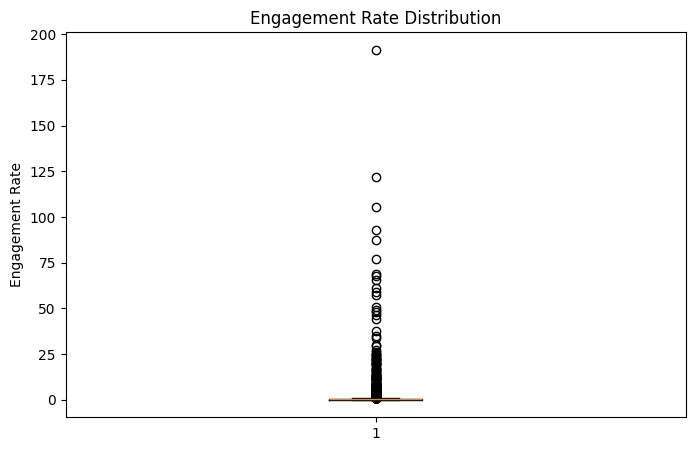

In [43]:
# 6. Box plot: Engagement rate
plt.figure(figsize=(8, 5))
plt.boxplot(df["engagement_rate"].dropna())
plt.title("Engagement Rate Distribution")
plt.ylabel("Engagement Rate")
plt.show()

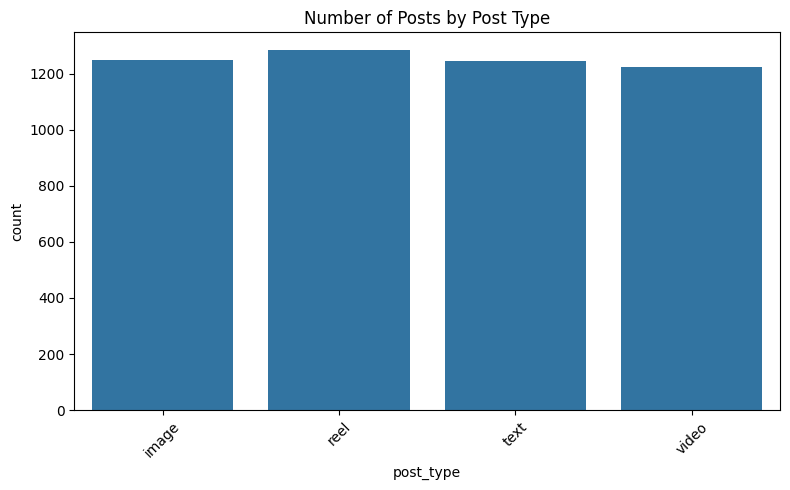

In [44]:
# 7. Count plot: Post type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="post_type")
plt.title("Number of Posts by Post Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

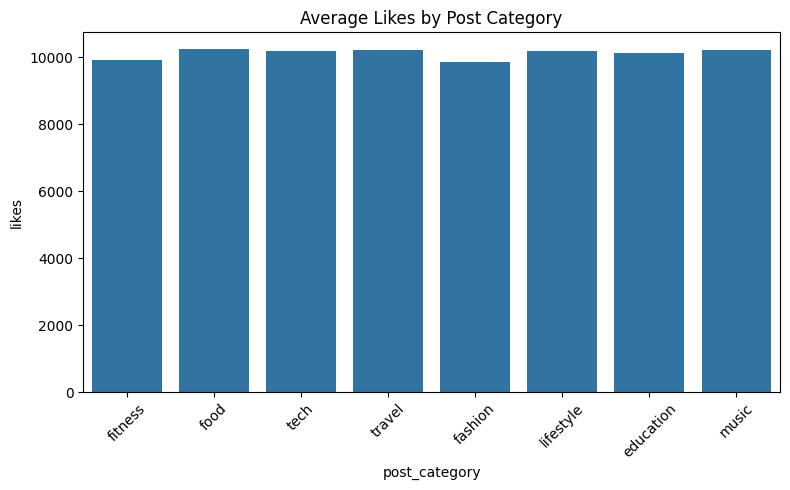

In [45]:
# 8. Bar plot: Average likes by category
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="post_category", y="likes", errorbar=None)
plt.title("Average Likes by Post Category")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

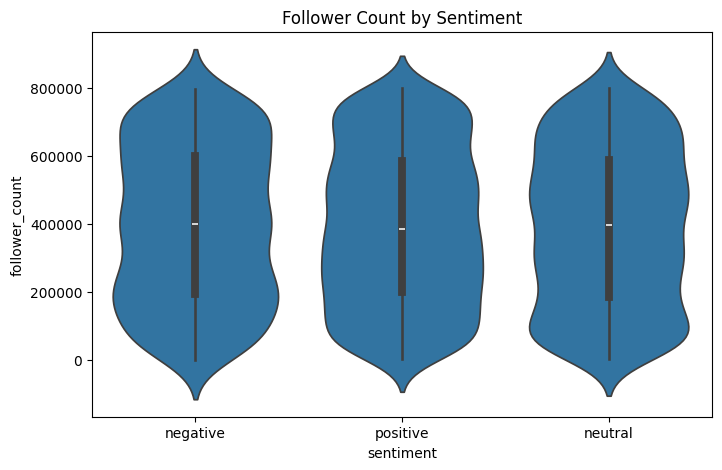

In [46]:
# 9. Violin plot: Followers vs Sentiment
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="sentiment", y="follower_count")
plt.title("Follower Count by Sentiment")
plt.show()

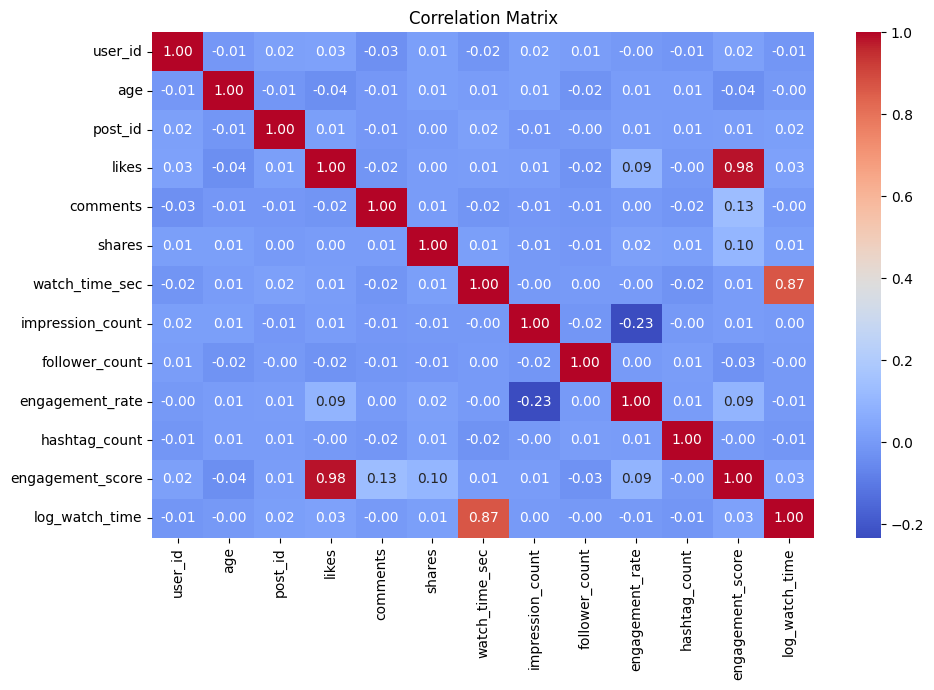

In [48]:
# 10. Heatmap: Correlation matrix
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()